In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# read the csv file
house = pd.read_csv("House Price Prediction Dataset.csv")

print("Dataset size:", house.shape)
display(house.head())
display(house.tail())


Dataset size: (2000, 10)


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119
1999,2000,2989,5,1,3,1903,Suburban,Fair,No,482525


In [2]:
print("Column names:")
print(house.columns.tolist())

print("\nData types:")
print(house.dtypes)

print("\nSummary of numerical columns:")
display(house.describe())

print("\nMissing values:")
print(house.isnull().sum())

print("\nDuplicate rows:", house.duplicated().sum())


Column names:
['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location', 'Condition', 'Garage', 'Price']

Data types:
Id            int64
Area          int64
Bedrooms      int64
Bathrooms     int64
Floors        int64
YearBuilt     int64
Location     object
Condition    object
Garage       object
Price         int64
dtype: object

Summary of numerical columns:


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000



Missing values:
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

Duplicate rows: 0


In [3]:
# Use area as the input and price as the value to predict
X = house[["Area"]]
y = house["Price"]

print("Input feature: Area")
print("Target: Price")


Input feature: Area
Target: Price


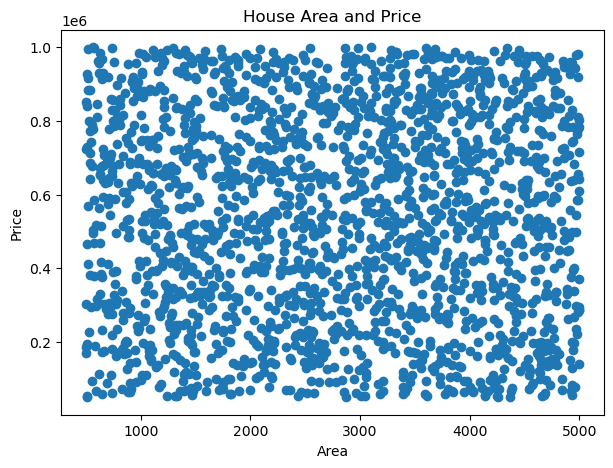

In [4]:
plt.figure(figsize=(7, 5))
plt.scatter(house["Area"], house["Price"])
plt.title("House Area and Price")
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 1600
Testing rows: 400


In [6]:
reg = LinearRegression()
reg.fit(X_train, y_train)

slope = reg.coef_[0]
intercept = reg.intercept_

print("Coefficient:", slope)
print("Intercept:", intercept)
print("Equation: Price =", round(intercept, 2), "+", round(slope, 2), "* Area")


Coefficient: -0.1838610419528592
Intercept: 536693.6793940249
Equation: Price = 536693.68 + -0.18 * Area


In [7]:
predicted = reg.predict(X_test)

results = pd.DataFrame({
    "Area": X_test["Area"].values,
    "Actual Price": y_test.values,
    "Predicted Price": predicted
})

display(results.head(10))


,Area,Actual Price,Predicted Price
0,633,514764,536577.295354
1,3856,694256,535984.711216
2,1598,66375,536399.869449
3,1705,650243,536380.196317
4,2564,223285,536222.259682
5,3219,468127,536101.830700
6,2565,513002,536222.075821
7,3131,911525,536118.010472
8,1775,723265,536367.326045
9,4109,339416,535938.194373


In [8]:
mae = mean_absolute_error(y_test, predicted)
mse = mean_squared_error(y_test, predicted)
rmse = mse ** 0.5
r2 = r2_score(y_test, predicted)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R-squared:", round(r2, 4))


MAE: 242478.32
MSE: 77856127383.18
RMSE: 279027.11
R-squared: -0.0007


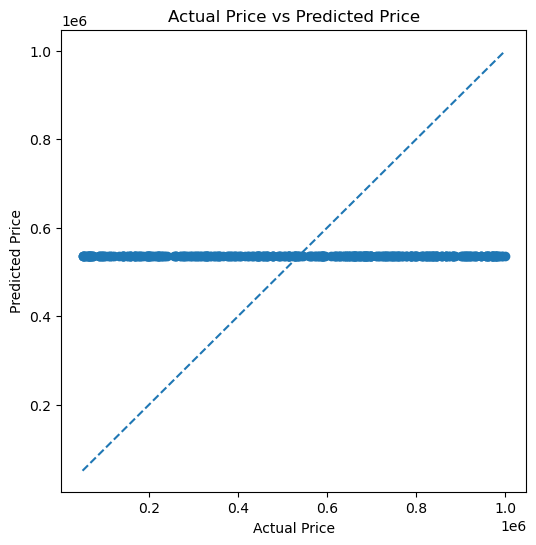

In [9]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predicted)
low = min(y_test.min(), predicted.min())
high = max(y_test.max(), predicted.max())
plt.plot([low, high], [low, high], "--")
plt.title("Actual Price vs Predicted Price")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.show()


In [10]:
# Example area; keep it within the range of areas in the dataset
new_house = pd.DataFrame({"Area": [2000]})
new_price = reg.predict(new_house)[0]

print("Area:", new_house.loc[0, "Area"])
print("Predicted house price:", round(new_price, 2))


Area: 2000
Predicted house price: 536325.96
